# Rain in Pakistan (Islamabad & Karachi) — Decision Trees & Random Forests

Predicting whether it will rain **tomorrow** (`rain_next_day`, i.e. at least 1 mm) in Islamabad and Karachi, using our own daily
ERA5-based dataset built from Open-Meteo (`build_dataset.py` -> `data/model_ready.csv`).

This notebook follows the same steps as the instructor's *Rain in Australia* notebook:
- Loading and sampling the dataset
- Preparing the data (chronological split, imputation, scaling, encoding)
- Training and evaluating a Decision Tree (with `max_depth` tuning)
- Training and evaluating a Random Forest (with basic hyperparameter tuning)
- Evaluation metrics: **Accuracy, Precision, Recall, F1-score, ROC-AUC**
- Section 13 adds extras specific to our project (class imbalance, threshold tuning, per-city and heavy-rain results)

**Differences from the Australia notebook (and why)** are marked with `NOTE:` in the cells.

## 1. Setup

In [4]:
!pip install pandas numpy scikit-learn matplotlib seaborn requests --quiet

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    average_precision_score
)

pd.set_option('display.max_columns', None)
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 14

RANDOM_STATE = 42
SAMPLE_FRACTION = 1.0     # our dataset is small (~19k rows) so we use all of it
DATA_PATH = 'model_ready.csv'

## 2. Load the Data

Our data comes from `build_dataset.py` (run it once; it downloads ERA5 daily data from Open-Meteo and writes `data/model_ready.csv`).
Each row is one city-day: weather variables on day *t*, lag/rolling features that only look backwards, and targets for day *t+1*.

In [6]:
if not os.path.exists(DATA_PATH):
    # Uncomment to build the dataset from inside the notebook (needs internet, takes a few minutes):
    # !python build_dataset.py
    raise FileNotFoundError(f'{DATA_PATH} not found. Run build_dataset.py first.')

raw_df_full = pd.read_csv(DATA_PATH, parse_dates=['date'])
print(raw_df_full.shape)
raw_df_full.head()

(18934, 73)


,city,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,shortwave_radiation_sum,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,et0_fao_evapotranspiration,sunshine_duration,daylight_duration,rh_mean,rh_min,rh_max,dewpoint_mean,pressure_msl_mean,pressure_msl_min,pressure_msl_max,surface_pressure_mean,cloud_mean,cloud_max,cloud_low_mean,cloud_mid_mean,cloud_high_mean,wind_speed_mean,winddir_sin_mean,winddir_cos_mean,vpd_mean,vpd_max,soil_moisture_mean,pressure_range,doy_sin,doy_cos,month,is_monsoon,temp_range,dewpoint_depression,precipitation_sum_lag1,rh_mean_lag1,pressure_msl_mean_lag1,dewpoint_mean_lag1,cloud_mean_lag1,temperature_2m_mean_lag1,precipitation_sum_lag2,rh_mean_lag2,pressure_msl_mean_lag2,dewpoint_mean_lag2,cloud_mean_lag2,temperature_2m_mean_lag2,precipitation_sum_lag3,rh_mean_lag3,pressure_msl_mean_lag3,dewpoint_mean_lag3,cloud_mean_lag3,temperature_2m_mean_lag3,precip_sum_3d,precip_sum_7d,precip_sum_14d,precip_sum_30d,rh_mean_3d,rh_mean_7d,pressure_change_1d,pressure_change_3d,days_since_rain,precip_next_day,rain_next_day,heavy_next_day,rain_class_next_day
0,Islamabad,2000-01-30,21.7,4.3,12.5,10.7,0.0,0.0,0.0,15.19,7.9,15.8,87,2.64,36796.63,37764.59,62.875000,33,81,4.970833,1014.566667,1012.0,1016.8,952.937500,10.083333,55,0.000000,5.208333,4.583333,5.425000,0.455484,0.012148,0.667083,1.64,0.374292,4.8,0.493468,0.869764,1,0,17.4,7.529167,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,0.0,64.291667,1020.362500,3.016667,7.375000,10.1,0.0,73.208333,1021.070833,5.750000,4.458333,10.8,0.0,15.4,15.6,91.0,62.750000,69.898810,-2.654167,-6.504167,4.0,7.3,1.0,0.0,1.0
1,Islamabad,2000-01-31,18.9,8.6,13.0,11.4,7.3,7.3,11.0,9.50,15.1,45.4,85,1.84,31565.30,37863.39,76.416667,50,94,8.600000,1012.708333,1010.2,1014.3,951.291667,71.500000,100,13.791667,58.541667,53.458333,8.133333,0.571455,0.200061,0.413333,1.03,0.384958,4.1,0.508356,0.861147,1,0,10.3,4.400000,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,0.0,64.291667,1020.362500,3.016667,7.375000,10.1,7.3,22.7,22.9,98.3,66.791667,70.922619,-1.858333,-7.654167,0.0,21.9,1.0,1.0,2.0
2,Islamabad,2000-02-01,11.0,7.9,9.9,8.2,21.9,21.9,24.0,3.15,11.1,29.9,50,0.67,4249.65,37963.49,85.041667,79,94,7.516667,1010.845833,1008.8,1014.0,948.916667,96.125000,100,93.916667,67.583333,54.583333,7.475000,0.644627,0.582040,0.185000,0.26,0.471250,5.2,0.523094,0.852275,2,0,3.1,2.383333,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,29.2,32.3,44.8,120.2,74.777778,71.845238,-1.862500,-6.375000,0.0,0.4,0.0,0.0,0.0
3,Islamabad,2000-02-02,15.8,7.8,11.1,9.4,0.4,0.4,2.0,11.02,8.4,16.9,35,1.71,33080.64,38064.75,75.416667,46,96,6.445833,1017.095833,1014.3,1019.8,955.020833,89.458333,100,30.833333,42.000000,58.333333,5.029167,0.463717,0.686101,0.373333,0.98,0.455208,5.5,0.537677,0.843151,2,0,8.0,4.654167,21.9,85.041667,1010.845833,7.516667,96.125000,9.9,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,29.6,29.6,45.2,120.6,78.958333,71.190476,6.250000,2.529167,1.0,0.0,0.0,0.0,0.0
4,Islamabad,2000-02-03,18.7,5.8,11.6,9.5,0.0,0.0,0.0,14.64,8.4,24.5,10,2.46,36823.95,38167.06,63.958333,40,81,4.416667,1019.029167,1016.5,1021.2,956.933333,50.958333,96,3.708333,42.500000,24.666667,5.429167,0.021060,0.748573,0.584583,1.28,0.433917,4.7,0.552101,0.833777,2,0,12.9,7.183333,0.4,75.416667,1017.095833,6.445833,89.458333,11.1,21.9,85.041667,1010.845833,7.516667,96.125000,9.9,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,22.3,29.6,45.2,120.6,74.805556,69.869048,1.933333,6.320833,2.0,0.9,0.0,0.0,0.0


## 3. Sample a Fraction of the Data

The instructor samples 30% to keep training fast. Our data is small, so `SAMPLE_FRACTION = 1.0` keeps every day.

NOTE: if you ever lower the fraction, sampling happens *after* the lag features were computed, so rows are not broken.

In [7]:
raw_df = raw_df_full.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE).sort_values(['city', 'date']).reset_index(drop=True)
print('Full dataset :', raw_df_full.shape)
print('Used data    :', raw_df.shape)
raw_df.head()

Full dataset : (18934, 73)
Used data    : (18934, 73)


,city,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,shortwave_radiation_sum,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,et0_fao_evapotranspiration,sunshine_duration,daylight_duration,rh_mean,rh_min,rh_max,dewpoint_mean,pressure_msl_mean,pressure_msl_min,pressure_msl_max,surface_pressure_mean,cloud_mean,cloud_max,cloud_low_mean,cloud_mid_mean,cloud_high_mean,wind_speed_mean,winddir_sin_mean,winddir_cos_mean,vpd_mean,vpd_max,soil_moisture_mean,pressure_range,doy_sin,doy_cos,month,is_monsoon,temp_range,dewpoint_depression,precipitation_sum_lag1,rh_mean_lag1,pressure_msl_mean_lag1,dewpoint_mean_lag1,cloud_mean_lag1,temperature_2m_mean_lag1,precipitation_sum_lag2,rh_mean_lag2,pressure_msl_mean_lag2,dewpoint_mean_lag2,cloud_mean_lag2,temperature_2m_mean_lag2,precipitation_sum_lag3,rh_mean_lag3,pressure_msl_mean_lag3,dewpoint_mean_lag3,cloud_mean_lag3,temperature_2m_mean_lag3,precip_sum_3d,precip_sum_7d,precip_sum_14d,precip_sum_30d,rh_mean_3d,rh_mean_7d,pressure_change_1d,pressure_change_3d,days_since_rain,precip_next_day,rain_next_day,heavy_next_day,rain_class_next_day
0,Islamabad,2000-01-30,21.7,4.3,12.5,10.7,0.0,0.0,0.0,15.19,7.9,15.8,87,2.64,36796.63,37764.59,62.875000,33,81,4.970833,1014.566667,1012.0,1016.8,952.937500,10.083333,55,0.000000,5.208333,4.583333,5.425000,0.455484,0.012148,0.667083,1.64,0.374292,4.8,0.493468,0.869764,1,0,17.4,7.529167,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,0.0,64.291667,1020.362500,3.016667,7.375000,10.1,0.0,73.208333,1021.070833,5.750000,4.458333,10.8,0.0,15.4,15.6,91.0,62.750000,69.898810,-2.654167,-6.504167,4.0,7.3,1.0,0.0,1.0
1,Islamabad,2000-01-31,18.9,8.6,13.0,11.4,7.3,7.3,11.0,9.50,15.1,45.4,85,1.84,31565.30,37863.39,76.416667,50,94,8.600000,1012.708333,1010.2,1014.3,951.291667,71.500000,100,13.791667,58.541667,53.458333,8.133333,0.571455,0.200061,0.413333,1.03,0.384958,4.1,0.508356,0.861147,1,0,10.3,4.400000,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,0.0,64.291667,1020.362500,3.016667,7.375000,10.1,7.3,22.7,22.9,98.3,66.791667,70.922619,-1.858333,-7.654167,0.0,21.9,1.0,1.0,2.0
2,Islamabad,2000-02-01,11.0,7.9,9.9,8.2,21.9,21.9,24.0,3.15,11.1,29.9,50,0.67,4249.65,37963.49,85.041667,79,94,7.516667,1010.845833,1008.8,1014.0,948.916667,96.125000,100,93.916667,67.583333,54.583333,7.475000,0.644627,0.582040,0.185000,0.26,0.471250,5.2,0.523094,0.852275,2,0,3.1,2.383333,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,0.0,61.083333,1017.220833,3.141667,24.833333,11.0,29.2,32.3,44.8,120.2,74.777778,71.845238,-1.862500,-6.375000,0.0,0.4,0.0,0.0,0.0
3,Islamabad,2000-02-02,15.8,7.8,11.1,9.4,0.4,0.4,2.0,11.02,8.4,16.9,35,1.71,33080.64,38064.75,75.416667,46,96,6.445833,1017.095833,1014.3,1019.8,955.020833,89.458333,100,30.833333,42.000000,58.333333,5.029167,0.463717,0.686101,0.373333,0.98,0.455208,5.5,0.537677,0.843151,2,0,8.0,4.654167,21.9,85.041667,1010.845833,7.516667,96.125000,9.9,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,0.0,62.875000,1014.566667,4.970833,10.083333,12.5,29.6,29.6,45.2,120.6,78.958333,71.190476,6.250000,2.529167,1.0,0.0,0.0,0.0,0.0
4,Islamabad,2000-02-03,18.7,5.8,11.6,9.5,0.0,0.0,0.0,14.64,8.4,24.5,10,2.46,36823.95,38167.06,63.958333,40,81,4.416667,1019.029167,1016.5,1021.2,956.933333,50.958333,96,3.708333,42.500000,24.666667,5.429167,0.021060,0.748573,0.584583,1.28,0.433917,4.7,0.552101,0.833777,2,0,12.9,7.183333,0.4,75.416667,1017.095833,6.445833,89.458333,11.1,21.9,85.041667,1010.845833,7.516667,96.125000,9.9,7.3,76.416667,1012.708333,8.600000,71.500000,13.0,22.3,29.6,45.2,120.6,74.805556,69.869048,1.933333,6.320833,2.0,0.9,0.0,0.0,0.0


In [8]:
raw_df.dropna(subset=['rain_next_day'], inplace=True)
print(raw_df.shape)
print(raw_df.groupby('city')['rain_next_day'].mean().round(3).rename('share of rainy days'))

(18934, 73)
city
Islamabad    0.269
Karachi      0.049
Name: share of rainy days, dtype: float64


## 4. Train / Validation / Test Split

Split chronologically: train on earlier years, validate and test on later years.

NOTE: the instructor uses `<2015 / 2015 / >2015`. Our data covers 2000-2025, so we use
**train: 2000-2018, validation: 2019-2021, test: 2022-2025**.

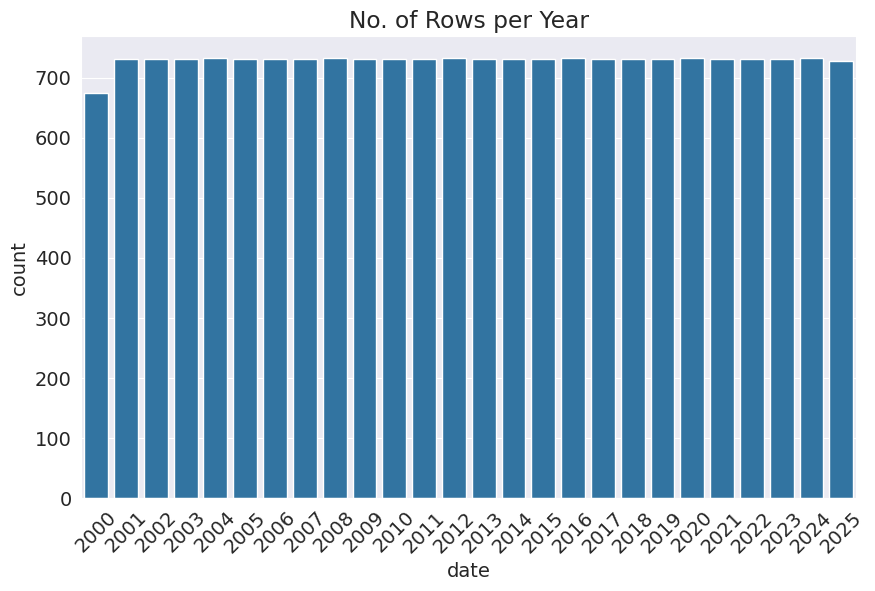

In [9]:
plt.title('No. of Rows per Year')
sns.countplot(x=raw_df.date.dt.year)
plt.xticks(rotation=45)
plt.show()

In [10]:
year = raw_df.date.dt.year

train_df = raw_df[year < 2019]
val_df   = raw_df[(year >= 2019) & (year <= 2021)]
test_df  = raw_df[year >= 2022]

print('train_df.shape :', train_df.shape)
print('val_df.shape   :', val_df.shape)
print('test_df.shape  :', test_df.shape)

train_df.shape : (13822, 73)
val_df.shape   : (2192, 73)
test_df.shape  : (2920, 73)


## 5. Input and Target Columns

NOTE (important): our file also contains the *answers* for tomorrow (`precip_next_day`, `rain_next_day`, `heavy_next_day`,
`rain_class_next_day`). These must **never** be used as inputs, otherwise the model would just read the answer. We drop all of them.

In [11]:
target_col = 'rain_next_day'
leak_cols = ['precip_next_day', 'rain_next_day', 'heavy_next_day', 'rain_class_next_day']
input_cols = [c for c in raw_df.columns if c not in ['date'] + leak_cols]

train_inputs, train_targets = train_df[input_cols].copy(), train_df[target_col].astype(int).copy()
val_inputs, val_targets     = val_df[input_cols].copy(), val_df[target_col].astype(int).copy()
test_inputs, test_targets   = test_df[input_cols].copy(), test_df[target_col].astype(int).copy()

numeric_cols = train_inputs.select_dtypes(include=np.number).columns.tolist()
categorical_cols = train_inputs.select_dtypes(include='object').columns.tolist()

print('Number of input columns:', len(input_cols))
print('Numeric columns    :', len(numeric_cols))
print('Categorical columns:', categorical_cols)

Number of input columns: 68
Numeric columns    : 67
Categorical columns: ['city']


## 6. Preprocessing

Impute missing numeric values, scale numeric features, and one-hot encode categorical features (`city`).

NOTE: the instructor fits the imputer/scaler/encoder on the *whole* dataset (`raw_df`). That lets test-set information leak into
preprocessing. We fit them on the **training set only**, then transform validation and test.

In [12]:
imputer = SimpleImputer(strategy='mean').fit(train_inputs[numeric_cols])

train_inputs[numeric_cols] = imputer.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols]   = imputer.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols]  = imputer.transform(test_inputs[numeric_cols])

In [13]:
scaler = MinMaxScaler().fit(train_inputs[numeric_cols])

train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols]   = scaler.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols]  = scaler.transform(test_inputs[numeric_cols])

In [14]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(train_inputs[categorical_cols])
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))

train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
val_inputs[encoded_cols]   = encoder.transform(val_inputs[categorical_cols])
test_inputs[encoded_cols]  = encoder.transform(test_inputs[categorical_cols])

In [15]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_val   = val_inputs[numeric_cols + encoded_cols]
X_test  = test_inputs[numeric_cols + encoded_cols]

X_train.shape, X_val.shape, X_test.shape

((13822, 69), (2192, 69), (2920, 69))

## 7. Evaluation Helper

A reusable function to compute **Accuracy, Precision, Recall, F1-score and ROC-AUC** for any fitted classifier.
Positive class = rain tomorrow (`1`).

In [16]:
POS = 1

def evaluate_model(model, X, y, pos_label=POS, name=''):
    preds = model.predict(X)
    pos_idx = list(model.classes_).index(pos_label)
    probs = model.predict_proba(X)[:, pos_idx]
    y_binary = (y == pos_label).astype(int)

    metrics = {
        'Accuracy':  accuracy_score(y, preds),
        'Precision': precision_score(y, preds, pos_label=pos_label, zero_division=0),
        'Recall':    recall_score(y, preds, pos_label=pos_label, zero_division=0),
        'F1 Score':  f1_score(y, preds, pos_label=pos_label, zero_division=0),
        'ROC AUC':   roc_auc_score(y_binary, probs),
    }
    return pd.Series(metrics, name=name)

def plot_roc(model, X, y, pos_label=POS, label=''):
    pos_idx = list(model.classes_).index(pos_label)
    probs = model.predict_proba(X)[:, pos_idx]
    y_binary = (y == pos_label).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, probs)
    plt.plot(fpr, tpr, label=f'{label} (AUC = {roc_auc_score(y_binary, probs):.3f})')

**Why we need two reference points:** only about 1 in 5 days is rainy, so a "model" that always says *No rain* already scores ~80% accuracy.
Always compare against these baselines (they are added to the final table in section 11).

In [17]:
print('Share of rainy days  train: %.3f | val: %.3f | test: %.3f' % (train_targets.mean(), val_targets.mean(), test_targets.mean()))
print('Accuracy of always predicting "No rain" on test: %.3f' % (1 - test_targets.mean()))

Share of rainy days  train: 0.152 | val: 0.172 | test: 0.182
Accuracy of always predicting "No rain" on test: 0.818


## 8. Decision Tree

In [18]:
dt_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_model.fit(X_train, train_targets)

DecisionTreeClassifier(random_state=42)

In [19]:
dt_results = pd.DataFrame([
    evaluate_model(dt_model, X_train, train_targets, name='Train'),
    evaluate_model(dt_model, X_val, val_targets, name='Validation'),
    evaluate_model(dt_model, X_test, test_targets, name='Test'),
])
dt_results

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Train,1.000000,1.000000,1.000000,1.000000,1.000000
Validation,0.831204,0.508997,0.525199,0.516971,0.709982
Test,0.817123,0.497258,0.512241,0.504638,0.698565


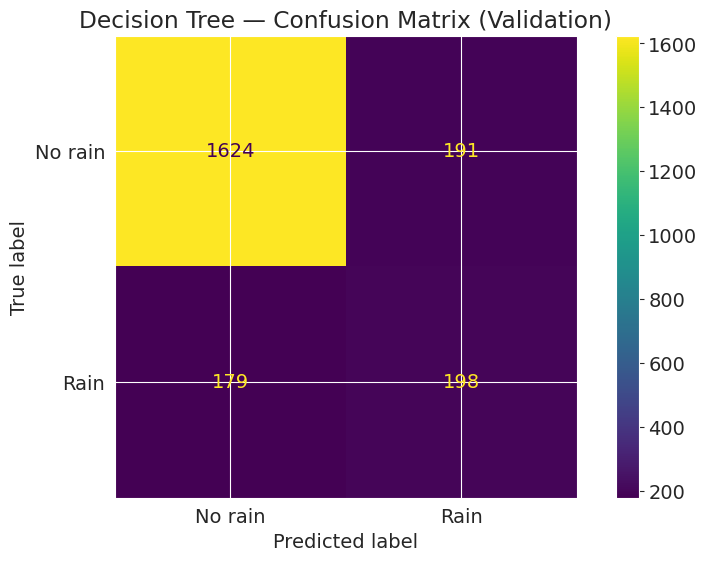

In [20]:
cm = confusion_matrix(val_targets, dt_model.predict(X_val), labels=dt_model.classes_)
ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot()
plt.title('Decision Tree — Confusion Matrix (Validation)')
plt.show()

### Tuning `max_depth`

A full-depth tree overfits the training data (train accuracy ~100%). Restricting `max_depth` improves generalization.

NOTE: the instructor picks the depth with the best validation *accuracy*. With rare rain, accuracy barely moves, so we also record
validation **ROC-AUC** and pick the depth by ROC-AUC.

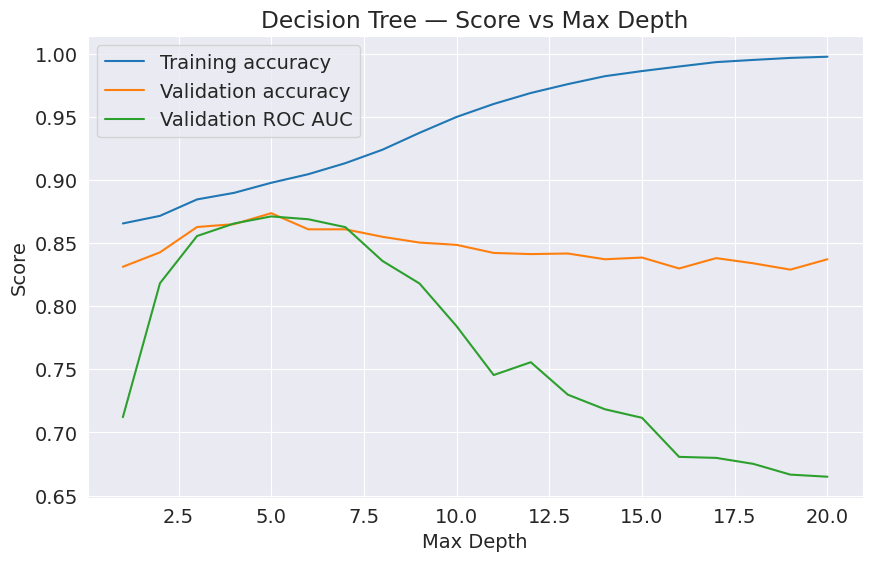

,Max Depth,Training Accuracy,Validation Accuracy,Validation ROC AUC
0,1,0.8655,0.8312,0.7121
1,2,0.8715,0.8426,0.8182
2,3,0.8845,0.8627,0.8555
3,4,0.8897,0.8650,0.8655
4,5,0.8977,0.8736,0.8711
5,6,0.9045,0.8609,0.8688
6,7,0.9133,0.8609,0.8626
7,8,0.9239,0.8549,0.8358
8,9,0.9373,0.8504,0.8179
9,10,0.9499,0.8485,0.7841


In [21]:
def max_depth_error(md):
    model = DecisionTreeClassifier(max_depth=md, random_state=RANDOM_STATE).fit(X_train, train_targets)
    return {
        'Max Depth': md,
        'Training Accuracy': model.score(X_train, train_targets),
        'Validation Accuracy': model.score(X_val, val_targets),
        'Validation ROC AUC': roc_auc_score(val_targets, model.predict_proba(X_val)[:, 1]),
    }

errors_df = pd.DataFrame([max_depth_error(md) for md in range(1, 21)])

plt.plot(errors_df['Max Depth'], errors_df['Training Accuracy'], label='Training accuracy')
plt.plot(errors_df['Max Depth'], errors_df['Validation Accuracy'], label='Validation accuracy')
plt.plot(errors_df['Max Depth'], errors_df['Validation ROC AUC'], label='Validation ROC AUC')
plt.xlabel('Max Depth')
plt.ylabel('Score')
plt.legend()
plt.title('Decision Tree — Score vs Max Depth')
plt.show()
errors_df.round(4)

In [22]:
best_depth = int(errors_df.loc[errors_df['Validation ROC AUC'].idxmax(), 'Max Depth'])
print('Best max_depth:', best_depth)

dt_model_tuned = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE).fit(X_train, train_targets)

dt_tuned_results = pd.DataFrame([
    evaluate_model(dt_model_tuned, X_train, train_targets, name='Train'),
    evaluate_model(dt_model_tuned, X_val, val_targets, name='Validation'),
    evaluate_model(dt_model_tuned, X_test, test_targets, name='Test'),
])
dt_tuned_results

Best max_depth: 5


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Train,0.897699,0.751095,0.489534,0.592742,0.910051
Validation,0.873631,0.695312,0.472149,0.562401,0.871066
Test,0.858562,0.683230,0.414313,0.515826,0.876707


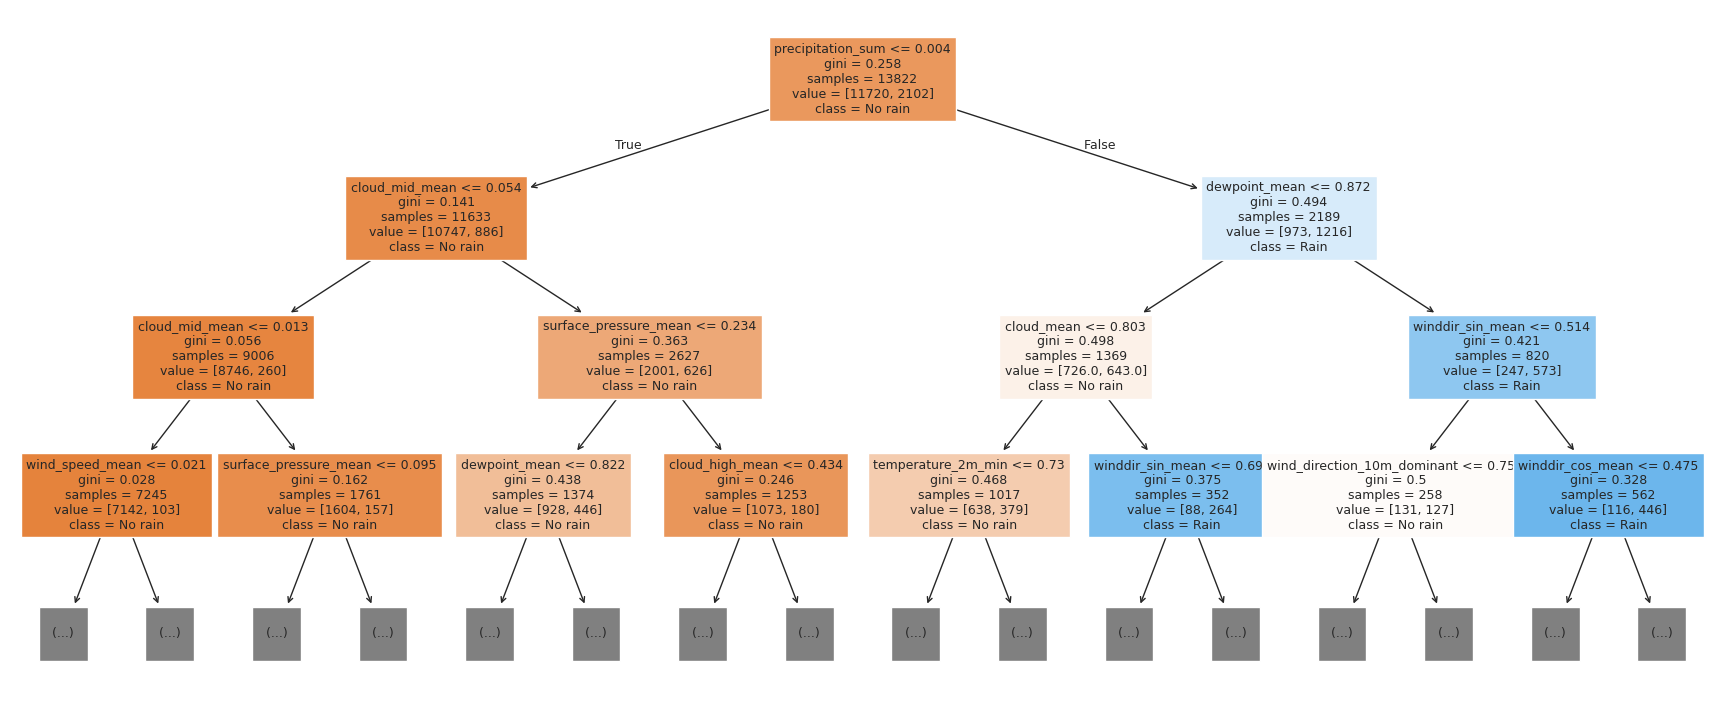

In [23]:
# Optional: look at the first levels of the tuned tree (good for explaining the model in the report)
plt.figure(figsize=(22, 9))
plot_tree(dt_model_tuned, max_depth=3, feature_names=X_train.columns, class_names=['No rain', 'Rain'], filled=True, fontsize=9)
plt.show()

## 9. Random Forest

In [24]:
rf_model = RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)
rf_model.fit(X_train, train_targets)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [25]:
rf_results = pd.DataFrame([
    evaluate_model(rf_model, X_train, train_targets, name='Train'),
    evaluate_model(rf_model, X_val, val_targets, name='Validation'),
    evaluate_model(rf_model, X_test, test_targets, name='Test'),
])
rf_results

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Train,1.000000,1.000000,1.000000,1.000000,1.000000
Validation,0.870438,0.688259,0.450928,0.544872,0.897371
Test,0.870890,0.716292,0.480226,0.574972,0.901778


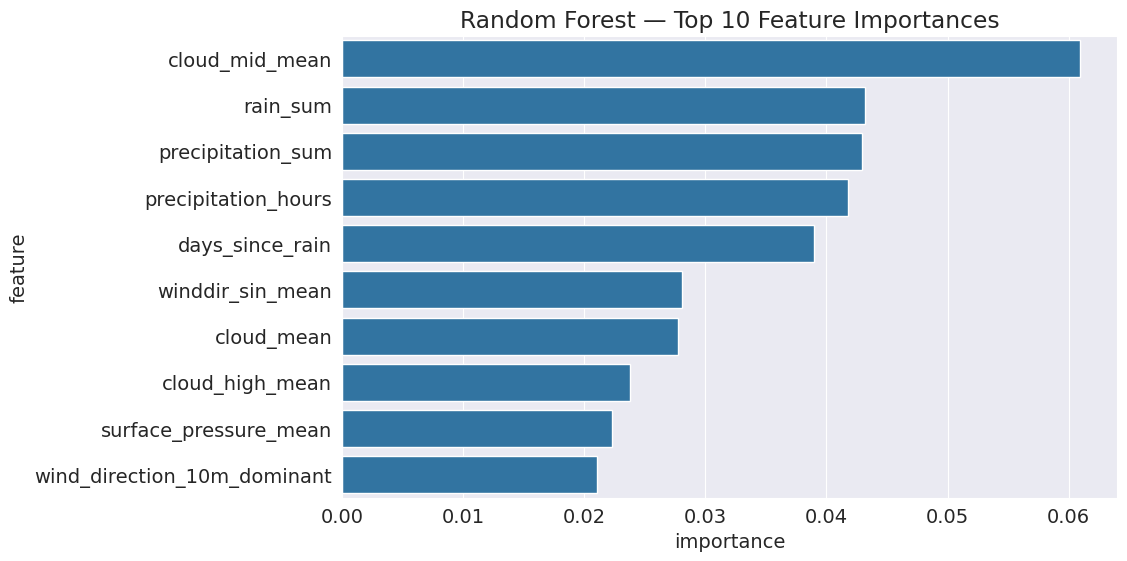

In [26]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.title('Random Forest — Top 10 Feature Importances')
sns.barplot(data=importance_df.head(10), x='importance', y='feature')
plt.show()

### Basic Hyperparameter Tuning

Try a few values of `n_estimators` and `max_depth` and pick the combination with the best validation score
(ROC-AUC, for the same reason as above).

In [27]:
def test_params(**params):
    model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params).fit(X_train, train_targets)
    return (model.score(X_train, train_targets), model.score(X_val, val_targets),
            roc_auc_score(val_targets, model.predict_proba(X_val)[:, 1]))

param_grid = [
    {'n_estimators': 100, 'max_depth': None},
    {'n_estimators': 200, 'max_depth': None},
    {'n_estimators': 200, 'max_depth': 15},
    {'n_estimators': 300, 'max_depth': 20},
]

tuning_results = []
for params in param_grid:
    train_acc, val_acc, val_auc = test_params(**params)
    tuning_results.append({**params, 'Training Accuracy': train_acc,
                           'Validation Accuracy': val_acc, 'Validation ROC AUC': val_auc})

tuning_df = pd.DataFrame(tuning_results)
tuning_df.round(4)

,n_estimators,max_depth,Training Accuracy,Validation Accuracy,Validation ROC AUC
0,100,NaN,1.0000,0.8704,0.8974
1,200,NaN,1.0000,0.8745,0.9000
2,200,15.0,0.9912,0.8700,0.8991
3,300,20.0,1.0000,0.8736,0.9001


In [28]:
best_params = tuning_df.loc[tuning_df['Validation ROC AUC'].idxmax(), ['n_estimators', 'max_depth']].to_dict()
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['max_depth'] = None if pd.isna(best_params['max_depth']) else int(best_params['max_depth'])
print('Best params:', best_params)

rf_model_tuned = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **best_params).fit(X_train, train_targets)

rf_tuned_results = pd.DataFrame([
    evaluate_model(rf_model_tuned, X_train, train_targets, name='Train'),
    evaluate_model(rf_model_tuned, X_val, val_targets, name='Validation'),
    evaluate_model(rf_model_tuned, X_test, test_targets, name='Test'),
])
rf_tuned_results

Best params: {'n_estimators': 300, 'max_depth': 20}


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Train,1.000000,1.000000,1.000000,1.000000,1.000000
Validation,0.873631,0.698413,0.466844,0.559618,0.900072
Test,0.866781,0.697222,0.472693,0.563412,0.907607


## 10. ROC Curve Comparison

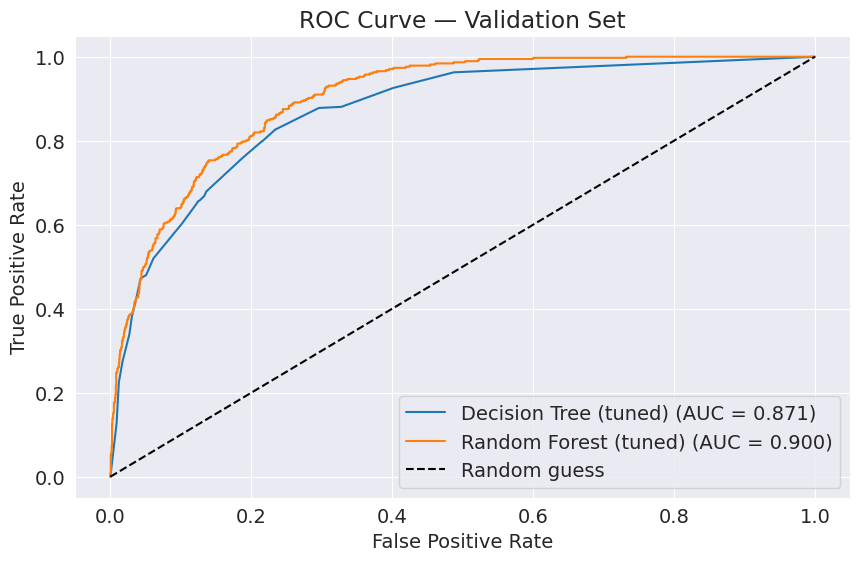

In [29]:
plt.figure()
plot_roc(dt_model_tuned, X_val, val_targets, label='Decision Tree (tuned)')
plot_roc(rf_model_tuned, X_val, val_targets, label='Random Forest (tuned)')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Validation Set')
plt.legend()
plt.show()

## 11. Final Comparison (Test Set)

Besides the two models, we add two simple baselines. A model is only useful if it beats them.

In [30]:
def metrics_from_preds(y, preds, probs, name):
    return pd.Series({
        'Accuracy': accuracy_score(y, preds),
        'Precision': precision_score(y, preds, zero_division=0),
        'Recall': recall_score(y, preds, zero_division=0),
        'F1 Score': f1_score(y, preds, zero_division=0),
        'ROC AUC': roc_auc_score(y, probs),
    }, name=name)

always_no = np.zeros(len(test_targets), dtype=int)
persistence = (test_df['precipitation_sum'] >= 1.0).astype(int).values   # "it rained today, so it rains tomorrow"

final_comparison = pd.DataFrame([
    metrics_from_preds(test_targets, always_no, np.zeros(len(test_targets)) + 1e-9 * np.arange(len(test_targets)), 'Baseline: always "No rain"'),
    metrics_from_preds(test_targets, persistence, persistence + 0.0, 'Baseline: persistence (rain today)'),
    evaluate_model(dt_model_tuned, X_test, test_targets, name='Decision Tree (tuned)'),
    evaluate_model(rf_model_tuned, X_test, test_targets, name='Random Forest (tuned)'),
])
final_comparison.round(4)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
"Baseline: always ""No rain""",0.8182,0.0000,0.0000,0.0000,0.3313
Baseline: persistence (rain today),0.8503,0.5887,0.5876,0.5881,0.7482
Decision Tree (tuned),0.8586,0.6832,0.4143,0.5158,0.8767
Random Forest (tuned),0.8668,0.6972,0.4727,0.5634,0.9076


## 12. Predicting on a New Input

The Australia notebook passes a dictionary with all raw columns. Our features include lags and rolling sums (they need the previous
days), so building them by hand is error-prone. Instead we predict for a **city and a date** that exists in our dataset: the function
looks up that row (which already contains all lags) and applies the same preprocessing.

In [31]:
def predict_for(city, date, model=rf_model_tuned):
    date = pd.to_datetime(date)
    row = raw_df_full[(raw_df_full.city == city) & (raw_df_full.date == date)]
    if row.empty:
        raise ValueError(f'No row for {city} on {date.date()}')
    input_df = row[input_cols].copy()
    input_df[numeric_cols] = imputer.transform(input_df[numeric_cols])
    input_df[numeric_cols] = scaler.transform(input_df[numeric_cols])
    input_df[encoded_cols] = encoder.transform(input_df[categorical_cols])
    X_input = input_df[numeric_cols + encoded_cols]
    prob_rain = model.predict_proba(X_input)[0][list(model.classes_).index(1)]
    pred = model.predict(X_input)[0]
    actual = row['rain_next_day'].iloc[0]
    return ('Rain' if pred == 1 else 'No rain'), prob_rain, ('Rain' if actual == 1 else 'No rain')

In [32]:
example = test_df[test_df.city == 'Islamabad'].iloc[100]
pred, prob, actual = predict_for('Islamabad', example['date'])
print(f"City: Islamabad | Date: {example['date'].date()} (predicting the NEXT day)")
print('Prediction      :', pred)
print('Probability rain:', round(prob, 3))
print('Actual outcome  :', actual)

City: Islamabad | Date: 2022-04-11 (predicting the NEXT day)
Prediction      : No rain
Probability rain: 0.245
Actual outcome  : No rain


## 13. Extensions for Our Project (not in the Australia notebook)

Rain is rare (about 18% of test days), so the default 0.5 cut-off usually finds too few rainy days (low recall). Here we
1. give rainy days more weight (`class_weight='balanced'`),
2. tune the decision threshold on the **validation** set (never on test),
3. report results per city,
4. repeat the idea for **heavy rain** (at least 10 mm), which is the more useful warning.

In [33]:
rf_bal = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample', **best_params).fit(X_train, train_targets)

def best_threshold(y_true, probs):
    ts = np.linspace(0.05, 0.9, 86)
    return ts[int(np.argmax([f1_score(y_true, (probs >= t).astype(int), zero_division=0) for t in ts]))]

val_probs  = rf_bal.predict_proba(X_val)[:, 1]
test_probs = rf_bal.predict_proba(X_test)[:, 1]
thr = best_threshold(val_targets, val_probs)
print('Threshold chosen on validation:', round(thr, 2))

def metrics_at(y, probs, t, name):
    return metrics_from_preds(y, (probs >= t).astype(int), probs, name)

ext = pd.DataFrame([
    metrics_at(test_targets, rf_model_tuned.predict_proba(X_test)[:, 1], 0.5, 'RF tuned (threshold 0.5)'),
    metrics_at(test_targets, test_probs, 0.5, 'RF balanced (threshold 0.5)'),
    metrics_at(test_targets, test_probs, thr, f'RF balanced (threshold {thr:.2f})'),
])
ext['PR AUC'] = [average_precision_score(test_targets, rf_model_tuned.predict_proba(X_test)[:, 1]),
                 average_precision_score(test_targets, test_probs), average_precision_score(test_targets, test_probs)]
ext.round(4)

Threshold chosen on validation: 0.28


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
RF tuned (threshold 0.5),0.8671,0.6981,0.4746,0.5650,0.9076,0.6905
RF balanced (threshold 0.5),0.8640,0.6791,0.4783,0.5613,0.9054,0.6677
RF balanced (threshold 0.28),0.8517,0.5729,0.7250,0.6401,0.9054,0.6677


In [34]:
# Per-city results on the test set (same threshold)
rows = []
for c in sorted(test_df.city.unique()):
    m = (test_df.city == c).values
    y = test_targets[m]
    r = metrics_at(y, test_probs[m], thr, c)
    r['Rainy days in test'] = int(y.sum()); r['Days'] = int(m.sum())
    rows.append(r)
pd.DataFrame(rows).round(4)

,Accuracy,Precision,Recall,F1 Score,ROC AUC,Rainy days in test,Days
Islamabad,0.7760,0.5616,0.7848,0.6547,0.8541,395.0,1460.0
Karachi,0.9274,0.6250,0.5515,0.5859,0.9518,136.0,1460.0


In [35]:
# Heavy rain tomorrow (>= 10 mm)
y_tr_h = train_df['heavy_next_day'].astype(int); y_va_h = val_df['heavy_next_day'].astype(int); y_te_h = test_df['heavy_next_day'].astype(int)
print('Heavy-rain days in test:', int(y_te_h.sum()), 'of', len(y_te_h))

rf_heavy = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample', **best_params).fit(X_train, y_tr_h)
thr_h = best_threshold(y_va_h, rf_heavy.predict_proba(X_val)[:, 1])
p_h = rf_heavy.predict_proba(X_test)[:, 1]
res_h = metrics_at(y_te_h, p_h, thr_h, f'Heavy rain RF (threshold {thr_h:.2f})')
res_h['PR AUC'] = average_precision_score(y_te_h, p_h)
res_h['Base rate'] = y_te_h.mean()
res_h.round(4).to_frame().T

Heavy-rain days in test: 126 of 2920


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC,Base rate
Heavy rain RF (threshold 0.34),0.9288,0.3136,0.5476,0.3988,0.9158,0.312,0.0432


## Summary

*(Fill in the numbers after running the notebook on our real data.)*

- **Decision Tree (tuned)** and **Random Forest (tuned)** were trained on our Islamabad + Karachi daily dataset (2000-2025) with a
  chronological split (train 2000-2018, validation 2019-2021, test 2022-2025).
- Both models were evaluated with **Accuracy, Precision, Recall, F1-score and ROC-AUC** on train/validation/test, and compared with
  two baselines (always "No rain", and persistence).
- The Random Forest usually gives higher ROC-AUC than a single tree, at the cost of interpretability; the tree is easier to explain.
- Because rain is rare, accuracy alone is misleading; we therefore also report Recall, F1, ROC-AUC and PR-AUC, and tune the decision
  threshold on the validation set.
- Limitations to state in the report: the "rain" values come from the ERA5 reanalysis (modelled, not gauge measurements), only two
  cities are used, and heavy-rain days are few (see the counts printed in section 13).